# EDA workstream E — regions, completeness and discrepancy

Owner: Project 5. Question: where do neurons and synapses sit, how complete is the record, and how often does an edge recur in another copy?

fafb (783) and malecns (v1.0). As the plan's Definitions say, malecns means its brain part: neurons with `in_brain`, the edges among them and, in edgeroi, brain neuropils only. The nerve-cord list passed to `add_provisional_flags` is provisional (`src/eda_e.py`, `MALECNS_NERVE_CORD`). E6 uses the public hemibrain v1.2 export (the plan pins v1.2.1).

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
import pandas as pd
from IPython.display import Image, display
from src import fetch_fafb, fetch_malecns
from src import eda_e_figures as F
from src.eda_e import brain_part
fafb = (fetch_fafb.load_neurons(), fetch_fafb.load_edges(), fetch_fafb.load_edgeroi())
mal_edges_all = fetch_malecns.load_edges()
mal = brain_part(fetch_malecns.load_neurons(), mal_edges_all, fetch_malecns.load_edgeroi())
from src.eda_e import columnar_cx_types
FAFB_COLUMNAR = columnar_cx_types(fafb[0])
print('malecns brain part:', [len(t) for t in mal])
STATS = {}

def show(key, result):
    paths, st, tabs = result
    STATS[key] = st
    print(json.dumps(st, indent=1, default=float))
    for p in paths:
        display(Image(filename=str(p)))
    return tabs

malecns brain part: [142745, 21361765, 24247846]


## E1. One neuron, one region (D15, D17)

{
 "neurons": 45168,
 "no_synapses": 318,
 "median_top_share": 0.5601480919796453,
 "gap_below_0.10": 11268,
 "gap_below_0.10_pct": 24.946865037194474
}


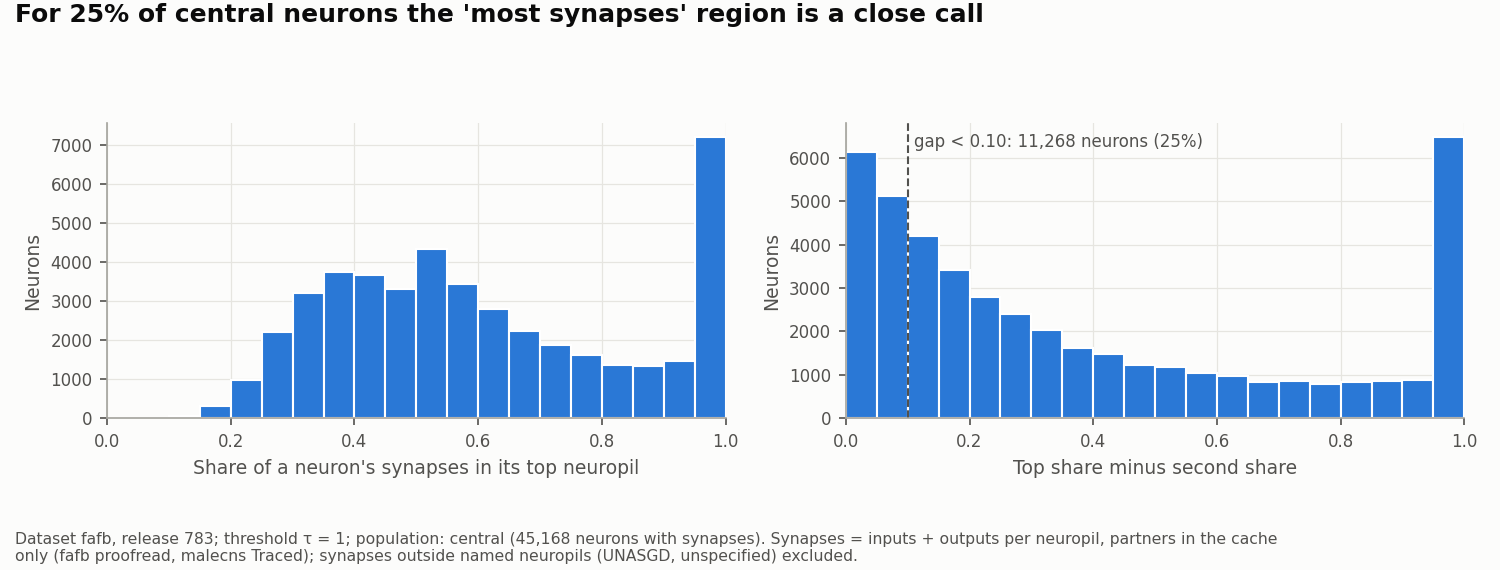

,neuron_id,cell_type,edges,input_synapses,top_frac_in,sum_of_fractions
0,720575940614297640,EPG,before (τ = 1),256,"EB 0.84, PB 0.11, FB 0.02",1.0
1,720575940614297640,EPG,after (τ = 10),32,"EB 0.81, GA_L 0.12, FB 0.06",1.0
2,720575940605213100,JO-DA,before (τ = 1),8,"AMMC_L 0.50, SAD 0.50",1.0
3,720575940605213100,JO-DA,after (τ = 10),0,—,0.0
4,720575940600646173,JO-EV6,before (τ = 1),57,"AMMC_L 0.56, SAD 0.44",1.0
5,720575940600646173,JO-EV6,after (τ = 10),0,—,0.0


In [3]:
tabs = show('E1_fafb', F.fig_e1(*fafb))
display(tabs['worked_example'])

{
 "neurons": 43870,
 "no_synapses": 107,
 "median_top_share": 0.5965442603373639,
 "gap_below_0.10": 8682,
 "gap_below_0.10_pct": 19.790289491679964
}


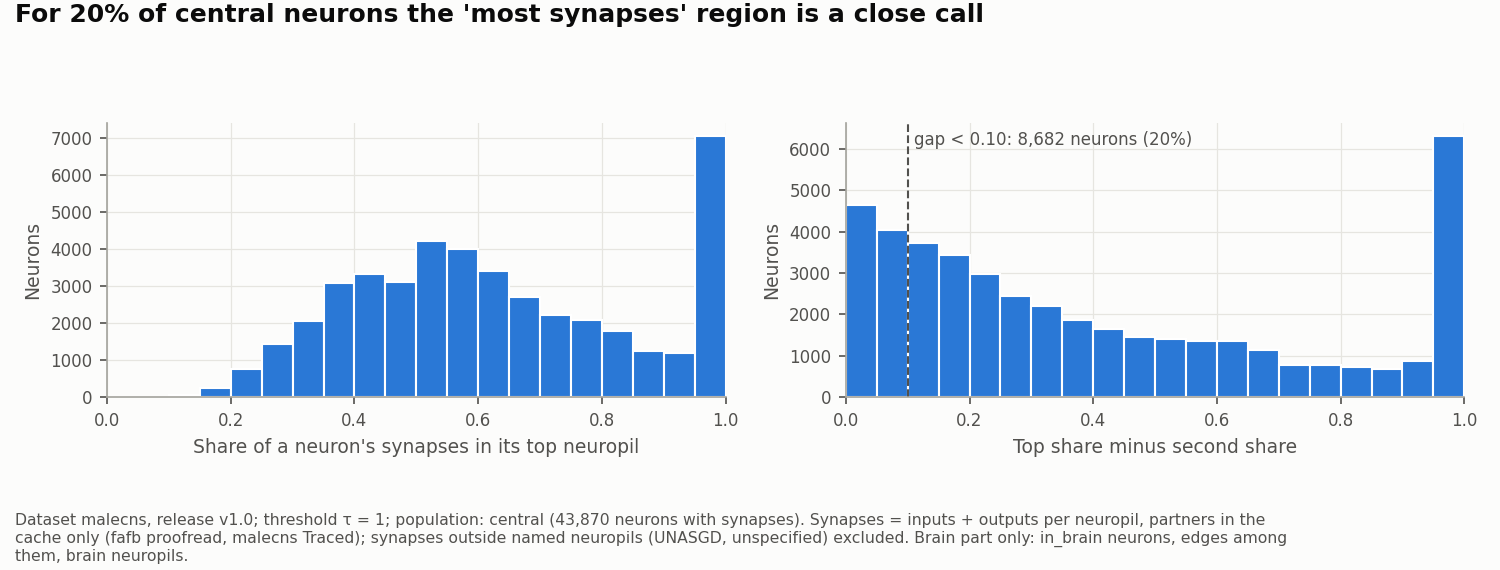

,neuron_id,cell_type,edges,input_synapses,top_frac_in,sum_of_fractions
0,10539,EPG,before (τ = 1),4828,"EB 0.91, PB 0.04, LAL(L) 0.04",1.0
1,10539,EPG,after (τ = 10),3984,"EB 0.92, PB 0.04, LAL(L) 0.04",1.0
2,10434,AN19B019,before (τ = 1),691,"PLP(L) 0.16, SMP(L) 0.13, CRE(L) 0.12",1.0
3,10434,AN19B019,after (τ = 10),255,"PLP(L) 0.16, ICL(L) 0.13, SCL(L) 0.12",1.0
4,12897,ANXXX120,before (τ = 1),108,"AVLP(R) 0.97, GNG 0.01, SAD 0.01",1.0
5,12897,ANXXX120,after (τ = 10),0,—,0.0


In [4]:
tabs = show('E1_malecns', F.fig_e1(*mal, ds='malecns', release='v1.0'))
display(tabs['worked_example'])

## E2. The optic-lobe share (D13, D14)

{
 "fafb": {
  "neurons": 139262,
  "clean central": 42100,
  "ambiguous": 5947,
  "clean optic": 90588,
  "no synapses": 627,
  "optic_by_super_class_pct": 55.679941405408506,
  "optic_by_region_flag_pct": 67.33782367049159,
  "optic_by_synapse_share_pct": 65.04861340494894,
  "ambiguous_pct": 4.270368083181342
 },
 "malecns": {
  "neurons": 142745,
  "clean central": 39573,
  "ambiguous": 6504,
  "clean optic": 96443,
  "no synapses": 225,
  "optic_by_super_class_pct": 62.62075729447616,
  "optic_by_region_flag_pct": 69.19191565378823,
  "optic_by_synapse_share_pct": 67.56313706259414,
  "ambiguous_pct": 4.556376755753266
 }
}


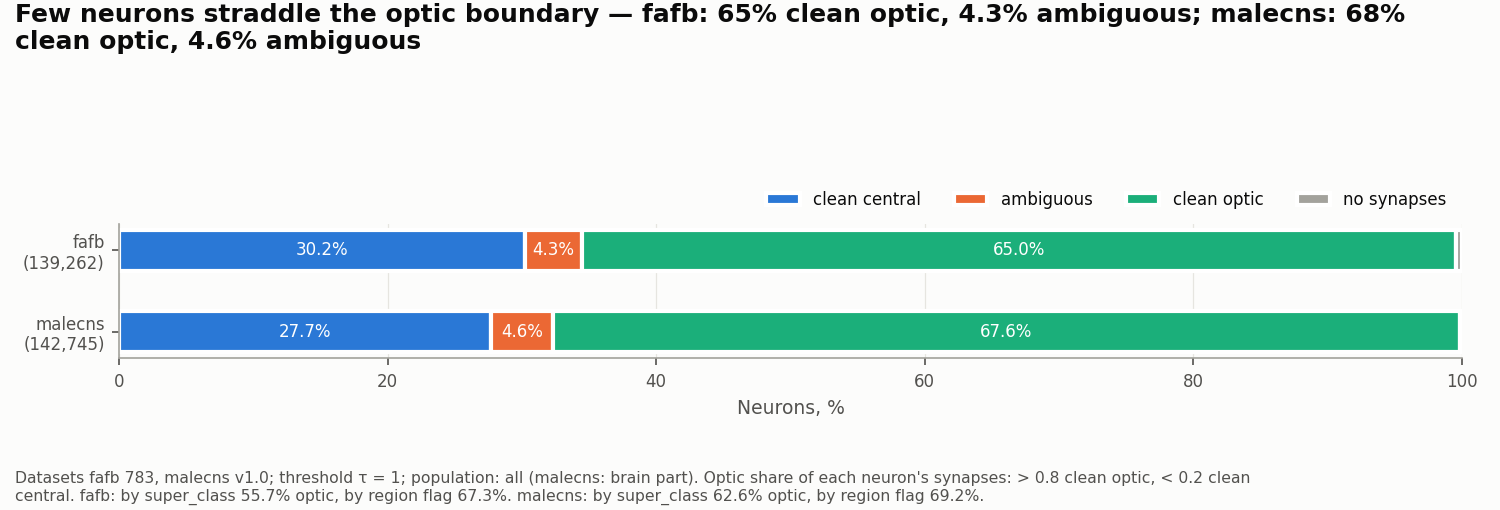

In [5]:
show('E2', F.fig_e2({'fafb': ('783', fafb[0], fafb[2]), 'malecns': ('v1.0', mal[0], mal[2])}));

## E3. The region-to-region map

{
 "fafb": {
  "regions": 38,
  "within_region_share": 0.5938392332902658,
  "synapses": 13378205
 },
 "malecns": {
  "regions": 36,
  "within_region_share": 0.6018415559228583,
  "synapses": 28286081
 }
}


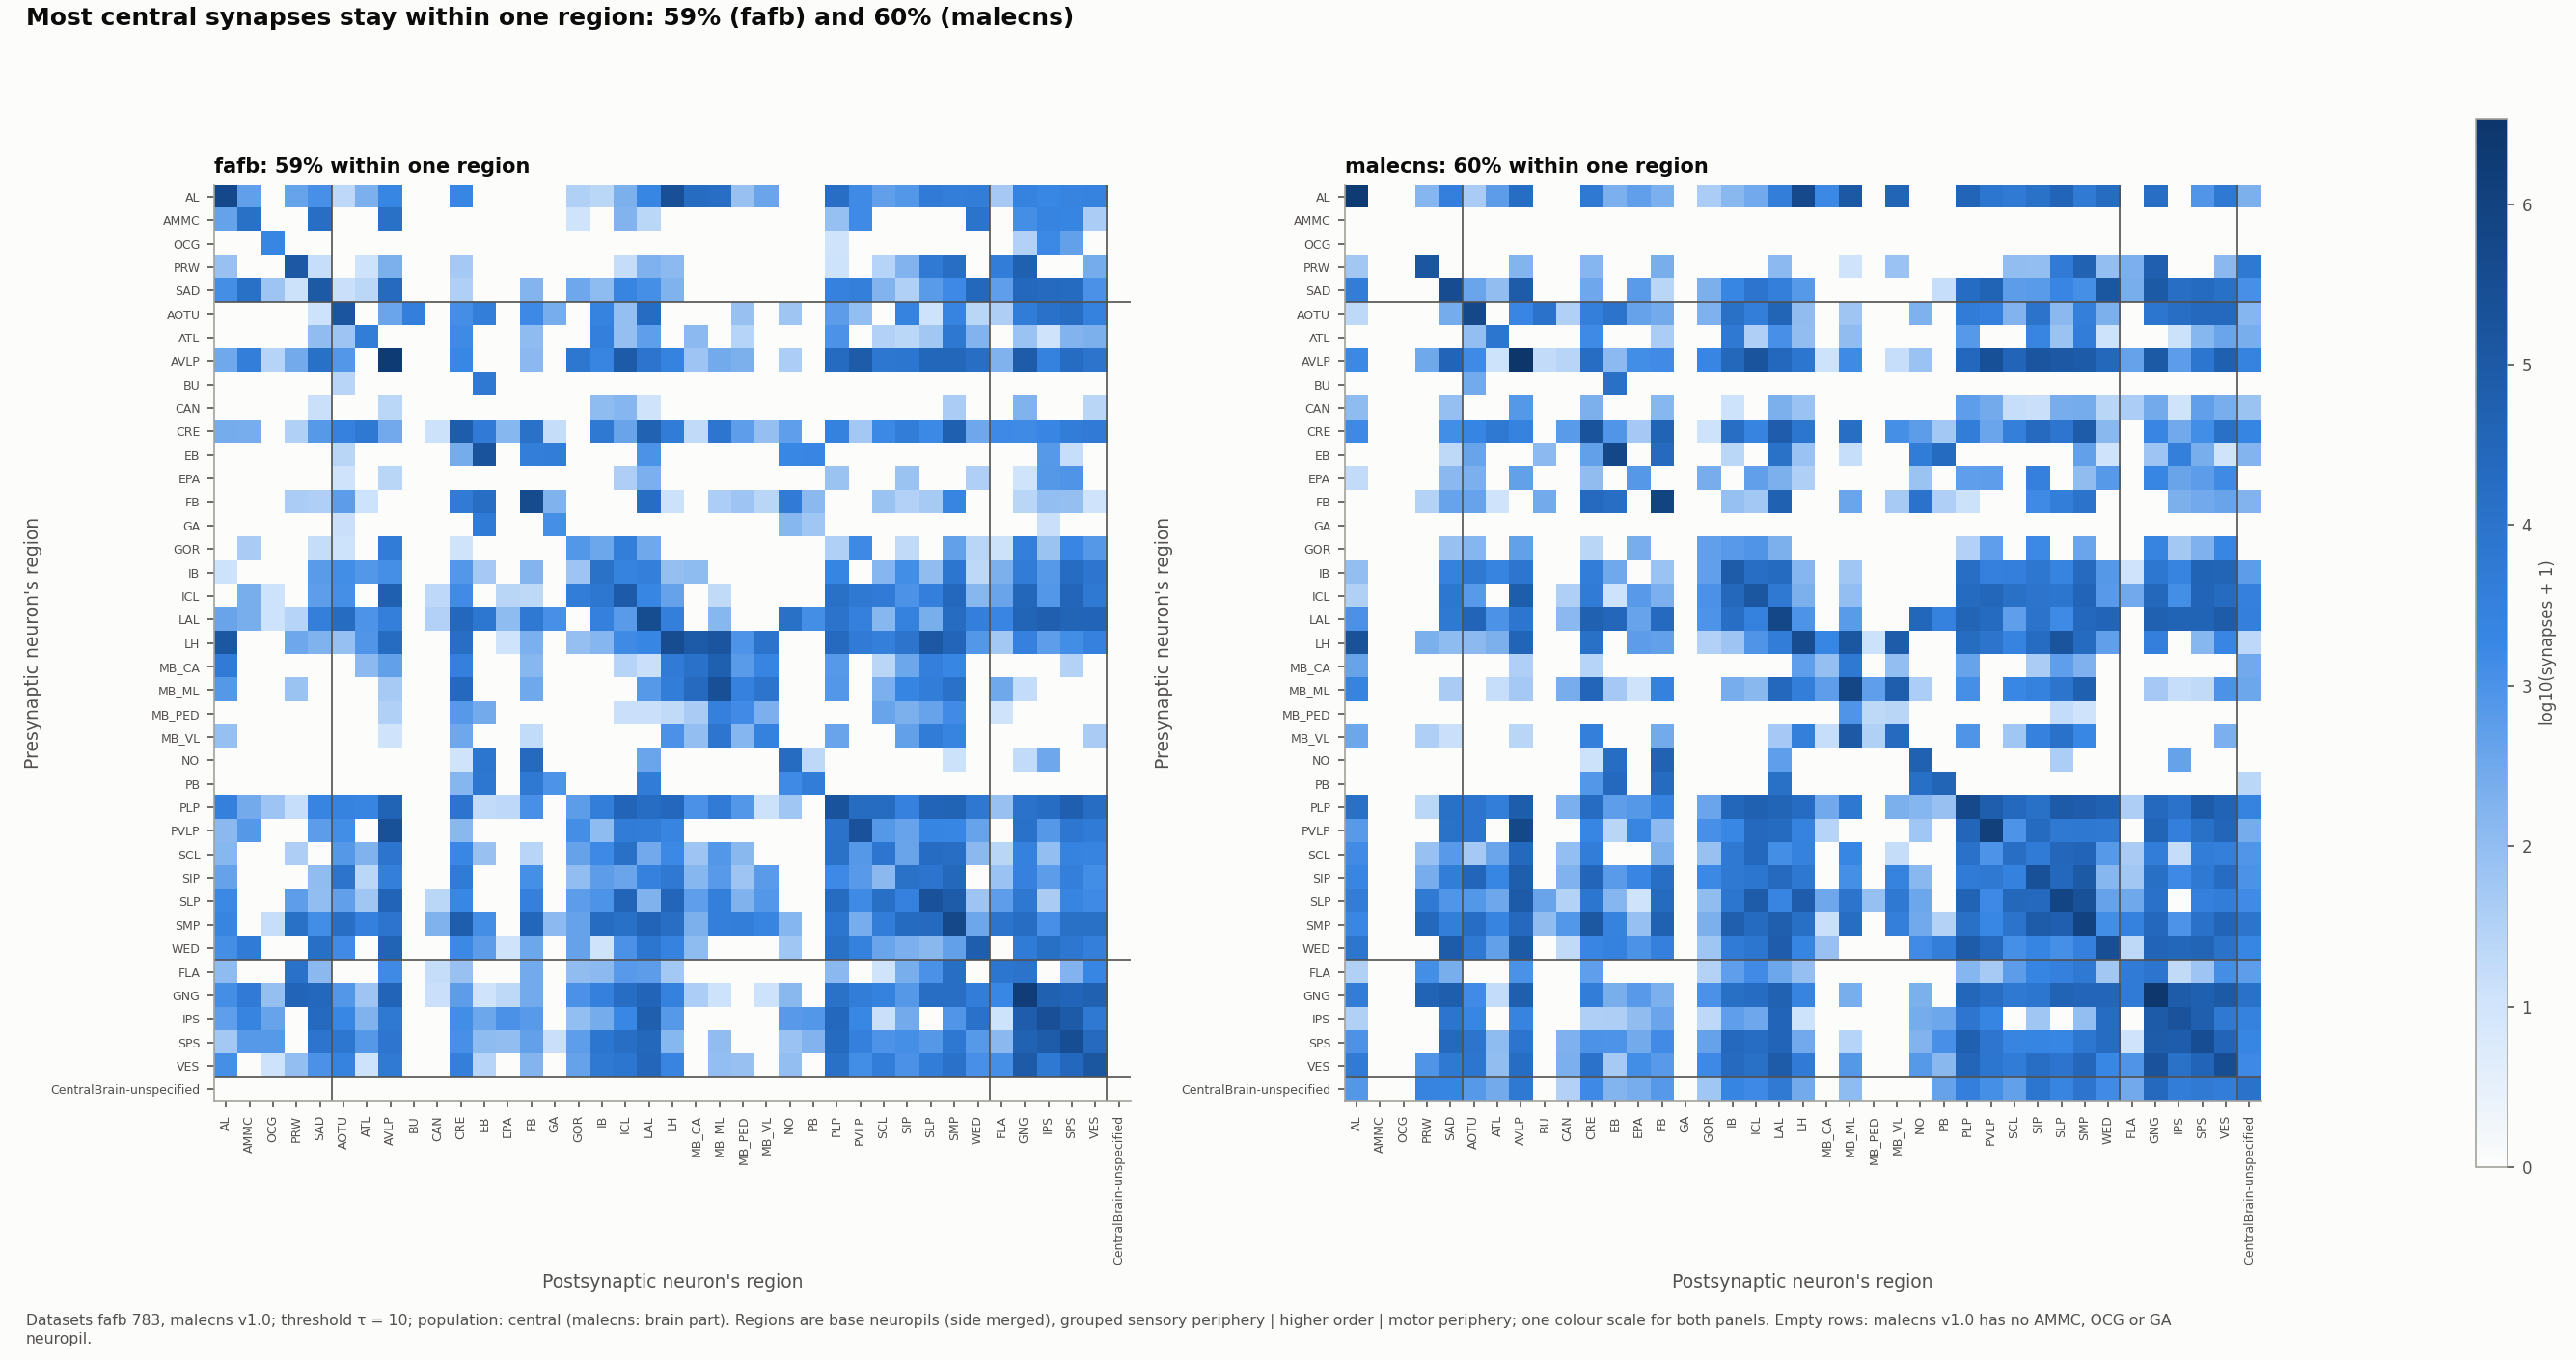

In [6]:
show('E3', F.fig_e3({'fafb': ('783', fafb[0], fafb[1]), 'malecns': ('v1.0', mal[0], mal[1])}));

## E4. How complete is each neuron's record

{
 "neurons": 43957,
 "median_ratio": 0.9611650485436893,
 "pooled_ratio": 0.9526927478218831,
 "over_1": 0,
 "below_0.5": 424,
 "median_ratio_brain_partners": 0.9558498896247241,
 "pooled_ratio_brain_partners": 0.9117623633443787,
 "median_ratio_ascending_brain_partners": 0.26903553299492383
}


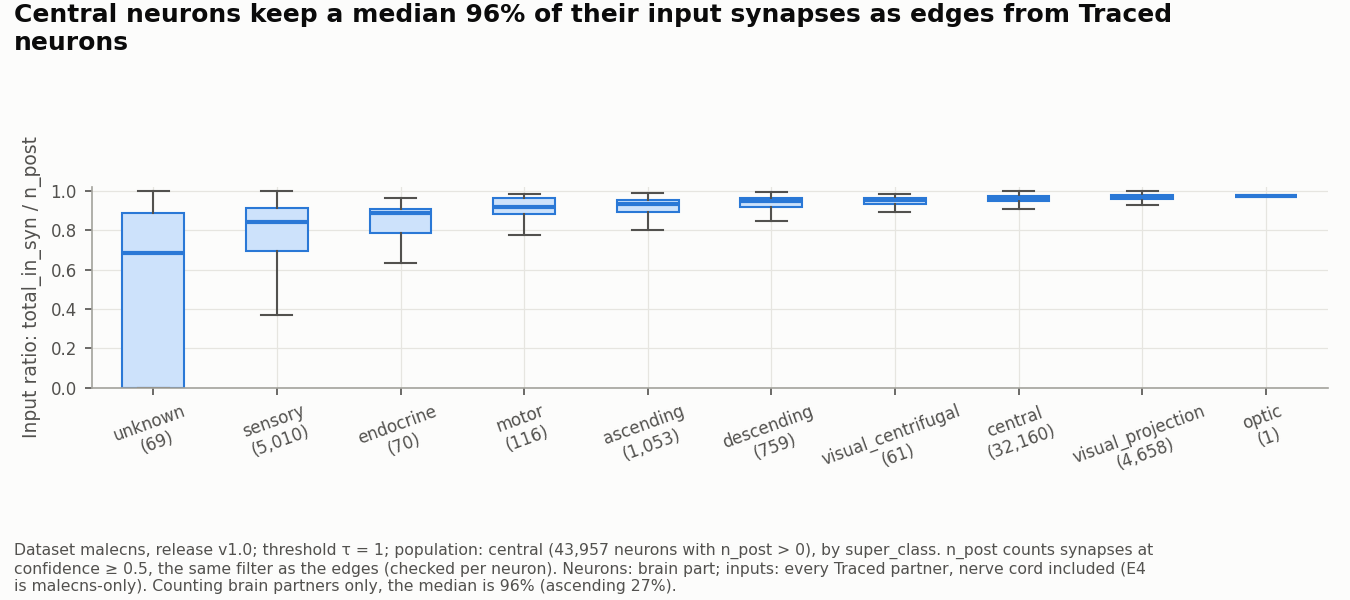

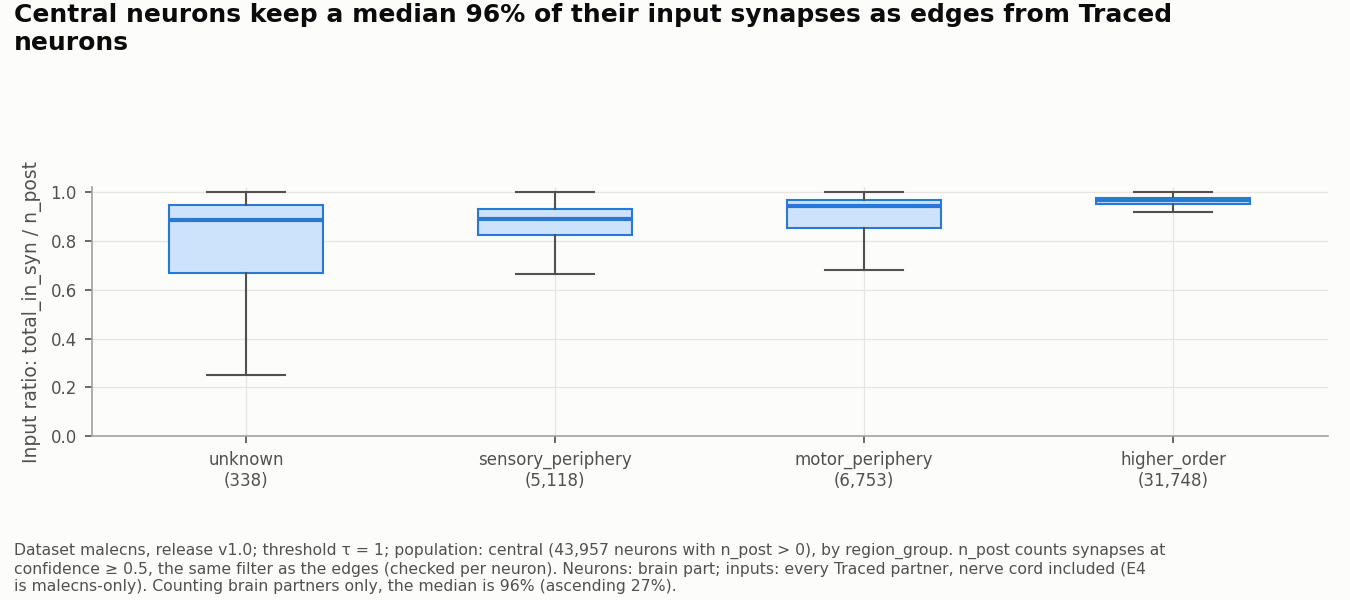

In [7]:
# The plan's E4 (malecns). n_post was checked to count only synapses at confidence >= 0.5.
# Inputs from every Traced partner (E4 is malecns-only, so the brain-part rule's reason does not apply).
show('E4_malecns', F.fig_e4_malecns(mal[0], mal_edges_all, mal[1]));

{
 "neurons": 45109,
 "median_ratio": 0.9516129032258065,
 "pooled_ratio": 0.9508321025098919,
 "over_1": 0
}


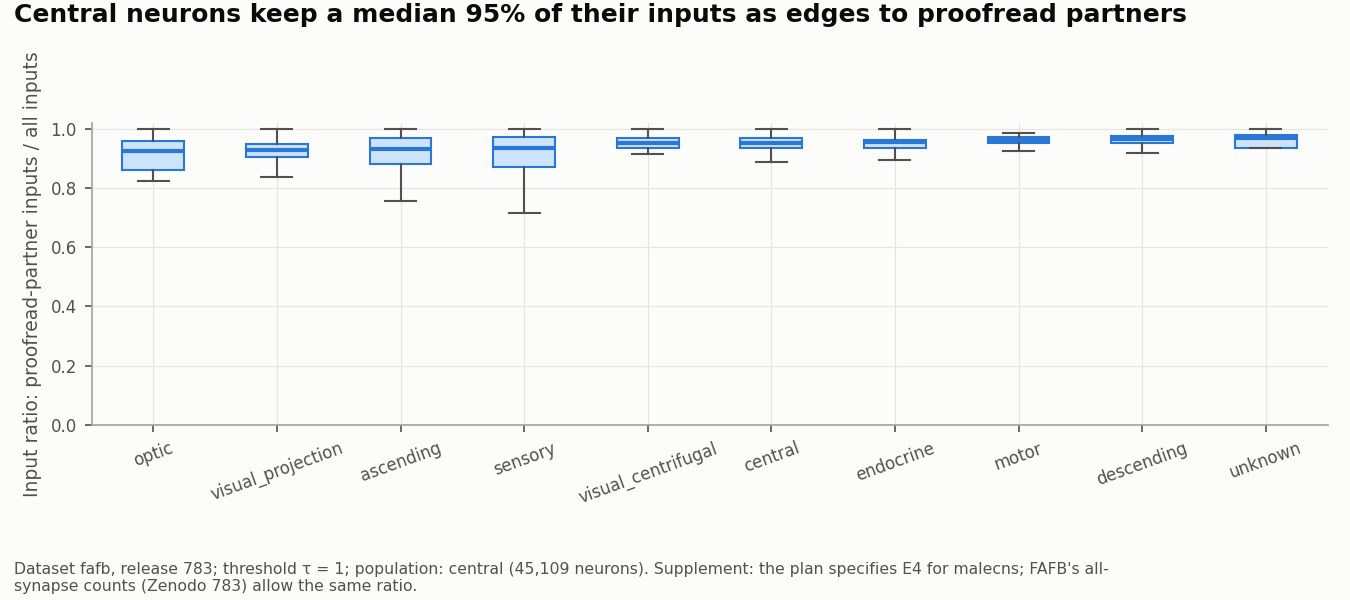

In [8]:
# FAFB supplement: FlyWire's all-synapse counts allow the same ratio.
show('E4supp_fafb', F.fig_e4_fafb(fafb[0], fafb[1], pd.read_feather(fetch_fafb.raw_file('neuropil_post'))));

## E5. Does an edge recur on the other side (D10)

{
 "central": {
  "type_pairs": 1656860,
  "share_1syn": 0.3151210402960113,
  "share_10plus": 0.9622144006192774
 },
 "optic": {
  "type_pairs": 87960,
  "share_1syn": 0.4606385474854796,
  "share_10plus": 0.9744367417677643
 }
}


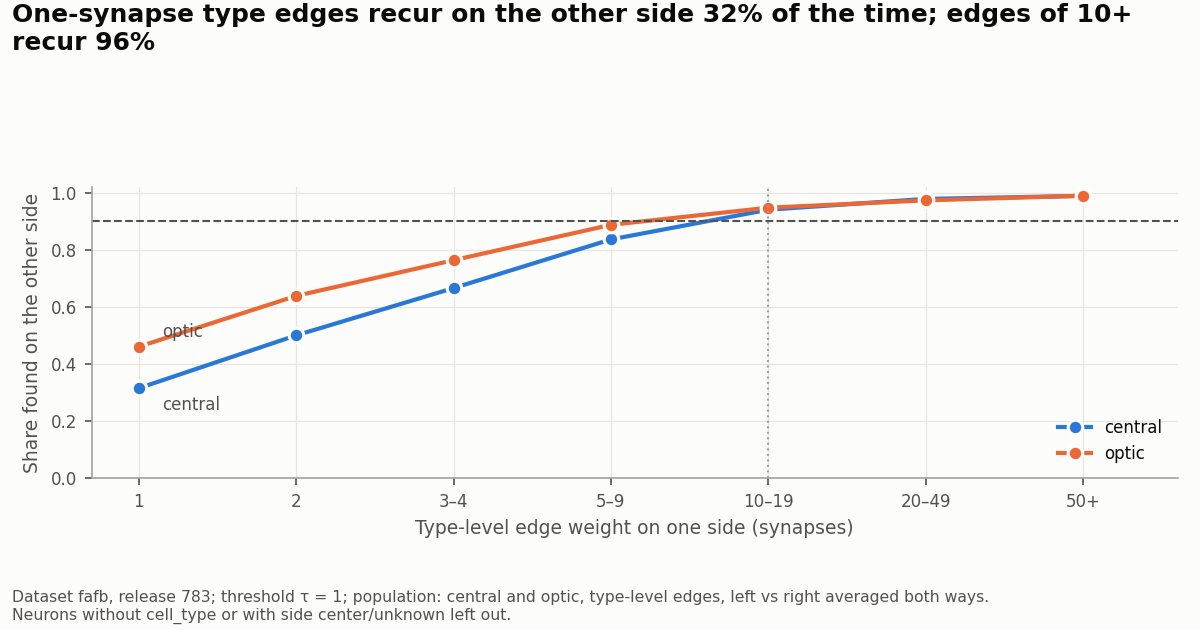

central                         optic                       
        share pairs_left pairs_right  share pairs_left pairs_right
bin                                                               
1       0.315     499460      511873  0.461      15254       15074
2       0.500     178810      185746  0.639       7849        7695
3–4     0.666     150294      158536  0.764       9010        8449
5–9     0.837     127035      137096  0.888      10341        9970
10–19   0.941      76172       84060  0.948       8399        8208
20–49   0.979      53294       59349  0.974       8692        8534
50+     0.990      27366       30467  0.990      13846       14637

,type_pairs,1,2,3–4,5–9,10–19,20–49,50+
min side count 0,23212,0.000,0.000,0.000,0.000,0.000,0.000,0.000
min side count 1,1327266,0.312,0.500,0.668,0.841,0.949,0.986,0.996
2–4,297250,0.346,0.530,0.690,0.858,0.952,0.988,0.997
5–19,8699,0.418,0.605,0.749,0.876,0.956,0.976,0.995
20+,433,0.557,0.735,0.837,0.948,0.987,1.000,1.000


,type_pairs,1,2,3–4,5–9,10–19,20–49,50+
all types,1656860,0.315,0.500,0.666,0.837,0.941,0.979,0.990
both types on both sides,1633648,0.319,0.506,0.673,0.845,0.950,0.987,0.996
equal left/right counts,1059871,0.320,0.514,0.686,0.860,0.961,0.991,0.999
"hemibrain-matched, both sides",843048,0.327,0.516,0.684,0.856,0.956,0.989,0.997


In [9]:
tabs = show('E5_fafb', F.fig_e5(fafb[0], fafb[1]))
display(pd.concat(tabs, axis=1).round(3))
from src.eda_e import e5_by_type_size, e5_restricted
display(e5_by_type_size(fafb[0], fafb[1]))  # recurrence rises with type size
display(e5_restricted(fafb[0], fafb[1]))    # restricting the type set barely moves it

{
 "central": {
  "type_pairs": 1934411,
  "share_1syn": 0.32426147590934384,
  "share_10plus": 0.9469482635301597
 },
 "optic": {
  "type_pairs": 87901,
  "share_1syn": 0.44782097925502284,
  "share_10plus": 0.9577228212780635
 }
}


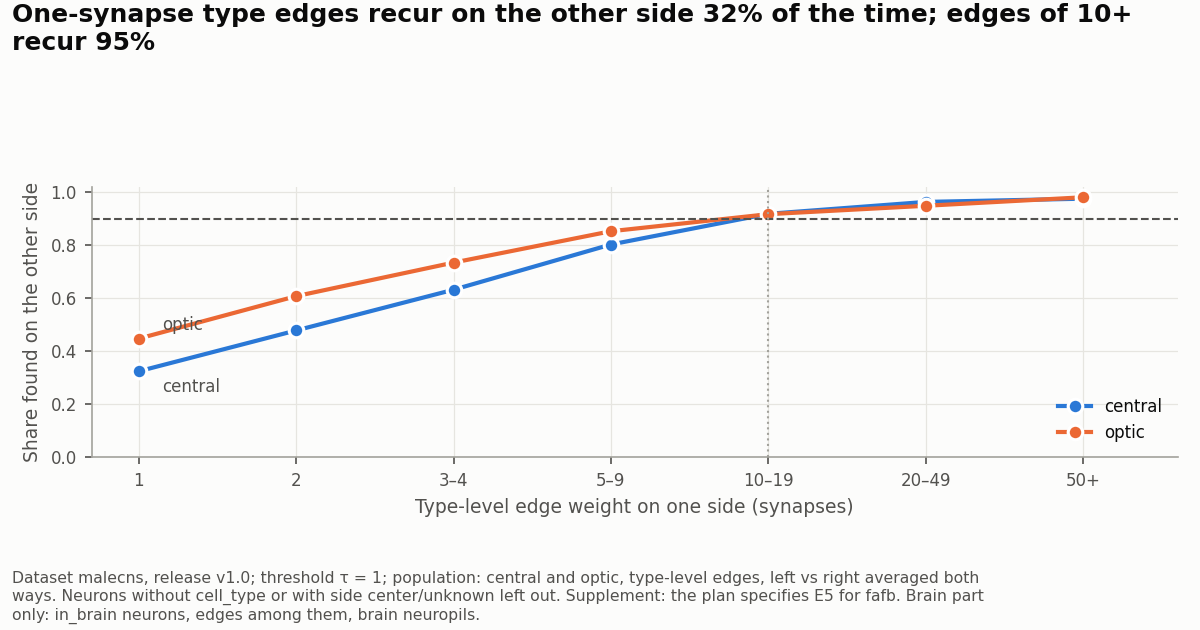

central                         optic                       
        share pairs_left pairs_right  share pairs_left pairs_right
bin                                                               
1       0.324     504055      514088  0.448      13244       14334
2       0.479     219219      221769  0.608       7019        7563
3–4     0.633     195975      199337  0.735       8049        8579
5–9     0.803     174276      177537  0.854       9453        9793
10–19   0.919     109773      114285  0.918       8094        8287
20–49   0.964      84151       87888  0.950       8252        8761
50+     0.977      51765       55458  0.982      15822       17463

,type_pairs,1,2,3–4,5–9,10–19,20–49,50+
min side count 0,60269,0.000,0.000,0.000,0.000,0.000,0.000,0.000
min side count 1,1445755,0.324,0.483,0.641,0.819,0.939,0.984,0.996
2–4,412270,0.356,0.511,0.665,0.832,0.943,0.986,0.996
5–19,15516,0.423,0.576,0.719,0.843,0.946,0.979,0.996
20+,601,0.630,0.678,0.800,0.929,0.973,0.979,1.000


In [10]:
# malecns supplement (the plan specifies E5 for fafb): the male's own left-right curve
tabs = show('E5supp_malecns', F.fig_e5(mal[0], mal[1], 'malecns', 'v1.0', item='E5supp',
            note='Supplement: the plan specifies E5 for fafb. ' + F.BRAIN_NOTE['malecns']))
display(pd.concat(tabs, axis=1).round(3))
display(e5_by_type_size(mal[0], mal[1]))

## E6. Does an edge recur in another animal

{
 "fafb vs malecns": {
  "match_groups": 7296,
  "regions": 40,
  "neurons_a": 19105,
  "neurons_b": 19025,
  "type_pairs": 1501129,
  "share_1syn": 0.31113298212537166,
  "share_10plus": 0.9047636379926308,
  "share_10_19": 0.8695497422971855,
  "a_to_b_10_19": 0.899997043082291,
  "b_to_a_10_19": 0.83910244151208
 },
 "fafb vs hemibrain": {
  "match_groups": 3909,
  "regions": 36,
  "neurons_a": 12254,
  "neurons_b": 13047,
  "type_pairs": 795652,
  "share_1syn": 0.3266781538860757,
  "share_10plus": 0.9187122324263426,
  "share_10_19": 0.894789539730269,
  "a_to_b_10_19": 0.9262505344164172,
  "b_to_a_10_19": 0.8633285450441207
 },
 "fafb vs malecns, hemibrain-matched types": {
  "match_groups": 3981,
  "regions": 39,
  "neurons_a": 11171,
  "neurons_b": 11363,
  "type_pairs": 733596,
  "share_1syn": 0.32096530480778906,
  "share_10plus": 0.9299611111730163,
  "share_10_19": 0.8969672258134747,
  "a_to_b_10_19": 0.9338960884555939,
  "b_to_a_10_19": 0.8600383631713555
 },
 "fafb le

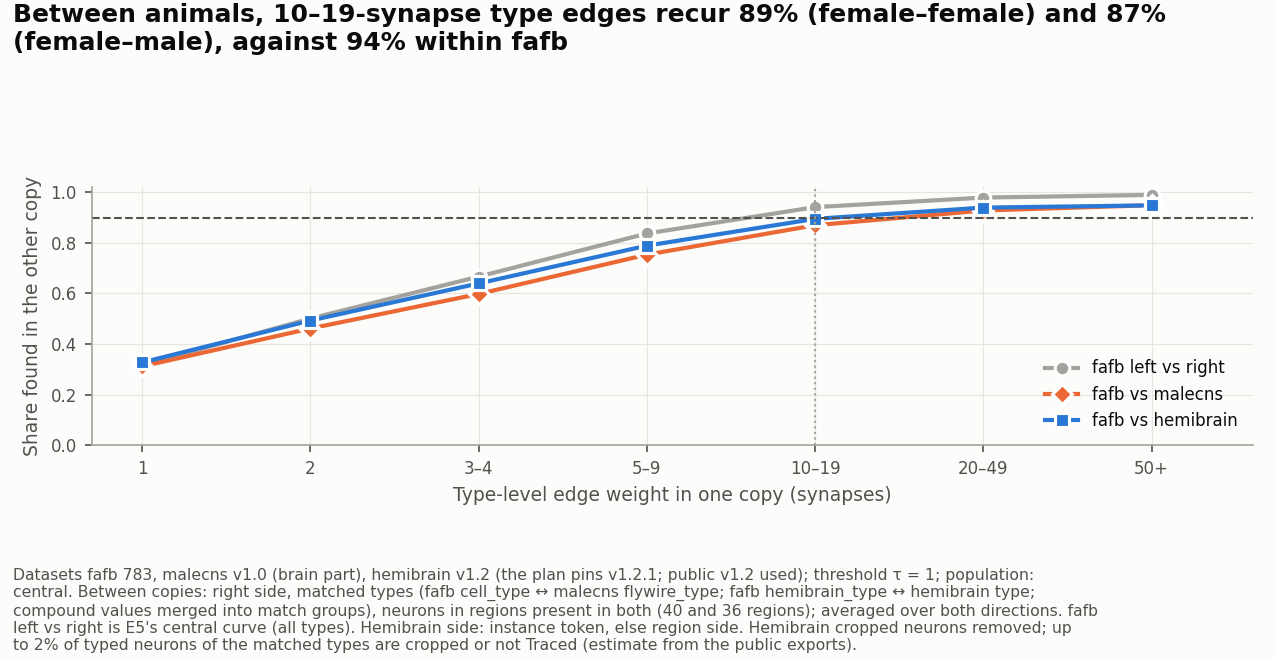

fafb left vs right                        fafb vs malecns                \
                   share pairs_left pairs_right           share a_to_b b_to_a   
bin                                                                             
1                  0.315     499460      511873           0.311  0.383  0.240   
2                  0.500     178810      185746           0.461  0.558  0.364   
3–4                0.666     150294      158536           0.598  0.697  0.498   
5–9                0.837     127035      137096           0.753  0.826  0.681   
10–19              0.941      76172       84060           0.870  0.900  0.839   
20–49              0.979      53294       59349           0.928  0.925  0.930   
50+                0.990      27366       30467           0.949  0.930  0.968   

                      fafb vs hemibrain                                \
      pairs_a pairs_b             share a_to_b b_to_a pairs_a pairs_b   
bin                                                                     
1      394402  419571             0.327  0.386  0.267  203334  258194   
2      145189  181525             0.492  0.558  0.427   76349   96957   
3–4    124553  163449             0.639  0.699  0.579   66585   82834   
5–9    109177  145740             0.789  0.836  0.741   59164   71471   
10–19   67638   94122             0.895  0.926  0.863   37424   43857   
20–49   49004   72852             0.939  0.964  0.915   28192   31585   
50+     26404   47144             0.948  0.963  0.933   16590   18098   

      fafb vs malecns, hemibrain-matched types                                
                                         share a_to_b b_to_a pairs_a pairs_b  
bin                                                                           
1                                        0.321  0.391  0.251  193943  207129  
2                                        0.477  0.575  0.378   71434   89812  
3–4                                      0.620  0.721  0.519   61626   80503  
5–9                                      0.778  0.856  0.701   54135   71864  
10–19                                    0.897  0.934  0.860   33644   46920  
20–49                                    0.955  0.965  0.944   24580   36492  
50+                                      0.976  0.972  0.980   13906   23944

In [11]:
# Hemibrain: public v1.2 export of non-cropped Traced neurons (the plan pins v1.2.1; see README).
from src import fetch_hemibrain
hemi = (fetch_hemibrain.load_neurons(), fetch_hemibrain.load_edges())

def cropped(groups):
    names = {t for g in groups for t in g.split(',')}
    return fetch_hemibrain.cropped_typed_share(names)

curves = show('E6', F.fig_e6(('783', fafb[0], fafb[1]), ('v1.0', mal[0], mal[1]), ('v1.2', *hemi), cropped))
display(pd.concat(curves, axis=1).round(3))

## E7. Central complex profile

{
 "fafb": {
  "PB": 100,
  "FB": 1896,
  "EB": 397,
  "NO": 224
 },
 "malecns": {
  "PB": 87,
  "FB": 1886,
  "EB": 419,
  "NO": 265
 }
}


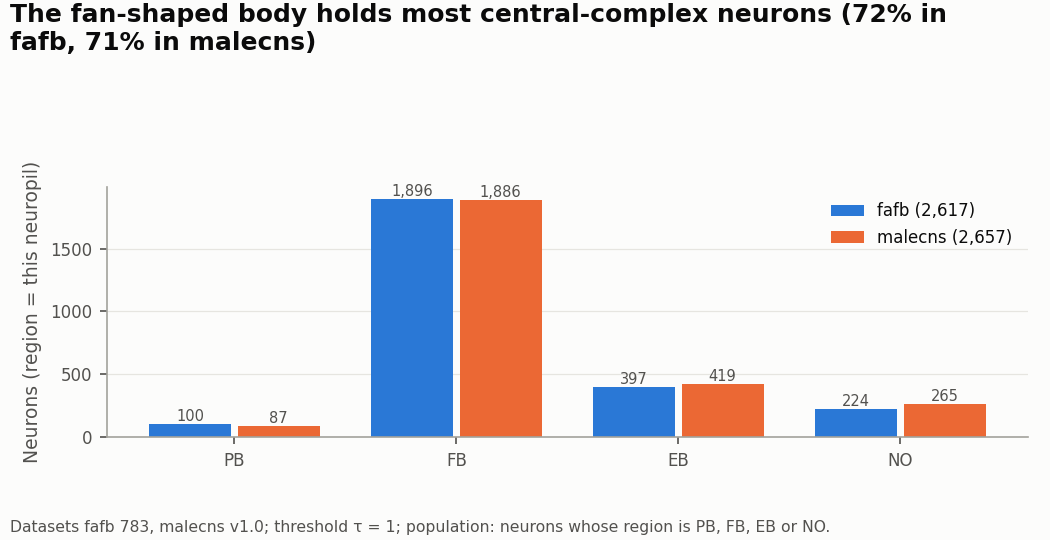

In [12]:
show('E7a', F.fig_e7a({'fafb': ('783', fafb[0]), 'malecns': ('v1.0', mal[0])}));

{
 "neurons_region_cx": 2617,
 "neurons_cell_class_cx": 2875,
 "overlap": 2560,
 "cell_types": 223,
 "untyped": 10,
 "types_8_to_16_on_both_sides": 31,
 "types_one_on_both_sides": 53,
 "edges_at_tau": 66982,
 "columnar_neurons": 1224,
 "columnar_block_fill_median": 0.02506265664160401,
 "columnar_connected_type_pairs": 393
}


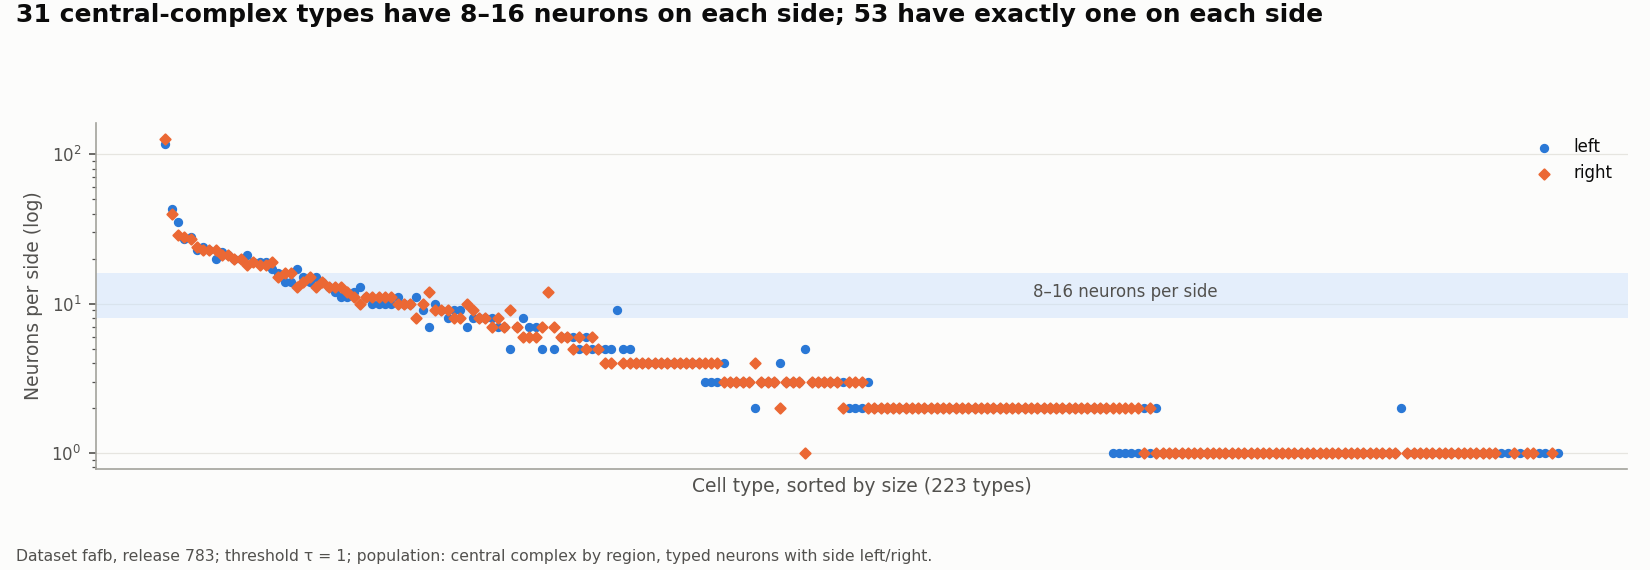

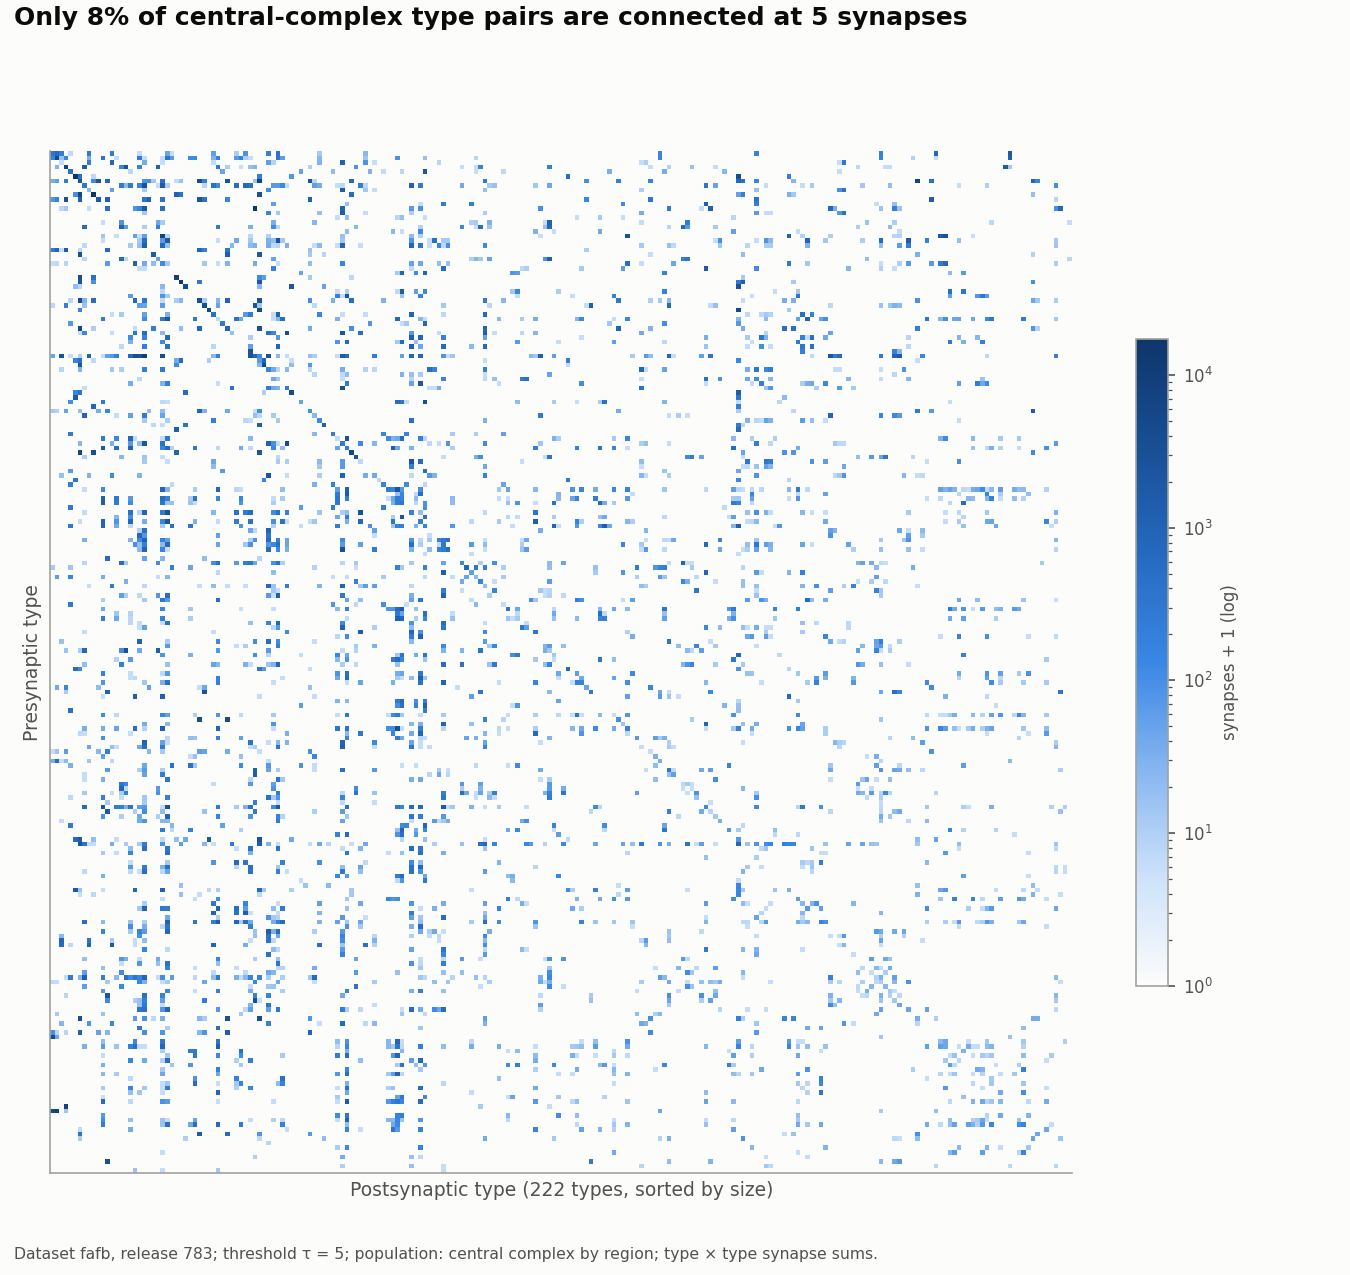

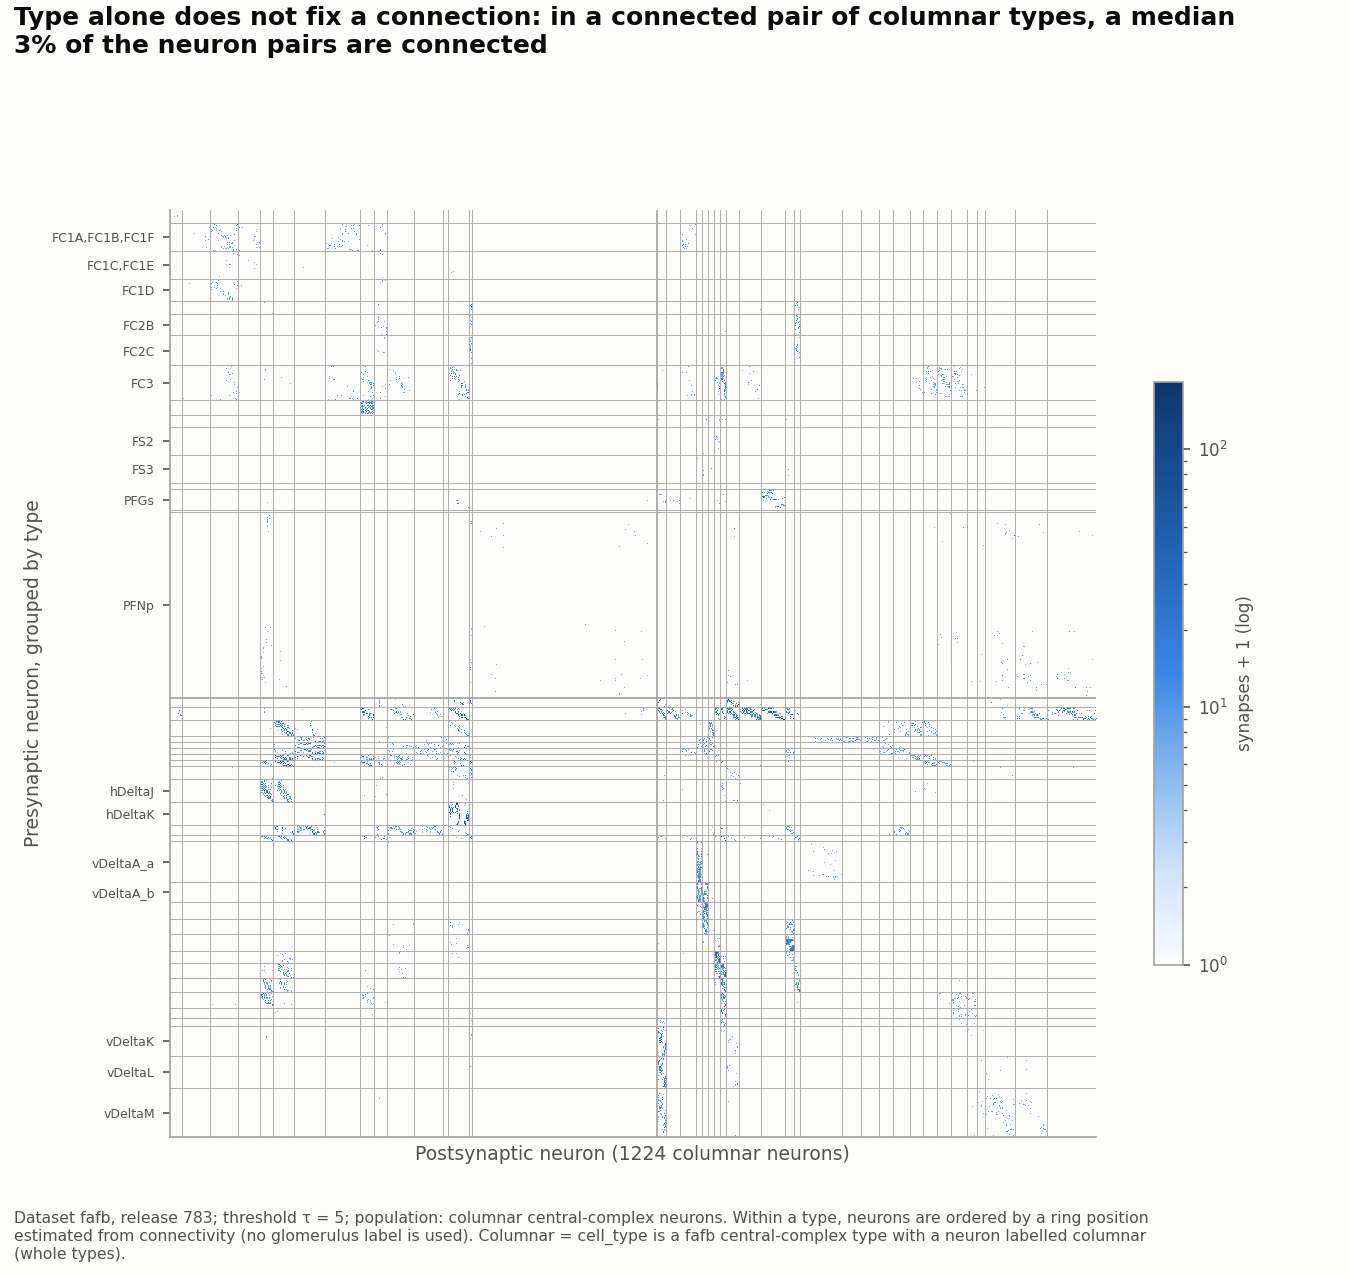

In [13]:
show('E7_fafb', F.fig_e7(fafb[0], fafb[1], FAFB_COLUMNAR));

{
 "neurons_region_cx": 2657,
 "neurons_cell_class_cx": 2950,
 "overlap": 2628,
 "cell_types": 282,
 "untyped": 1,
 "types_8_to_16_on_both_sides": 37,
 "types_one_on_both_sides": 81,
 "edges_at_tau": 127740,
 "columnar_neurons": 1311,
 "columnar_block_fill_median": 0.022222222222222223,
 "columnar_connected_type_pairs": 678
}


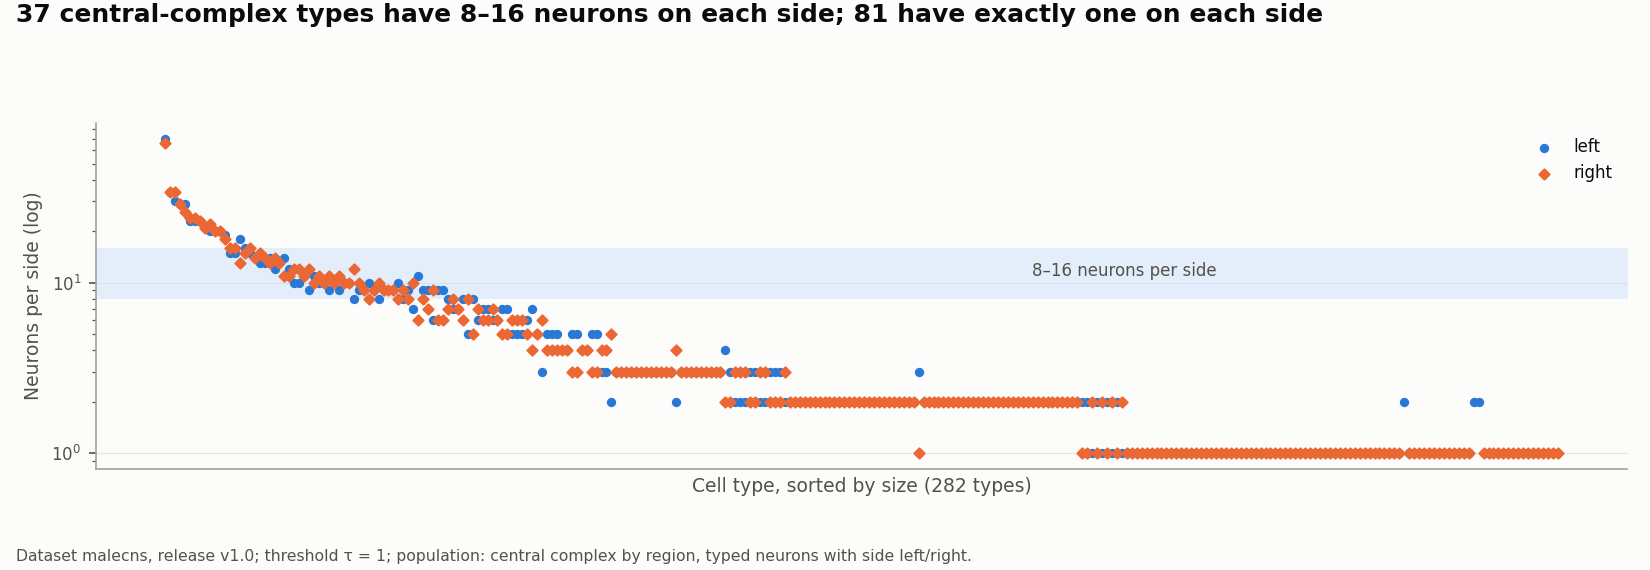

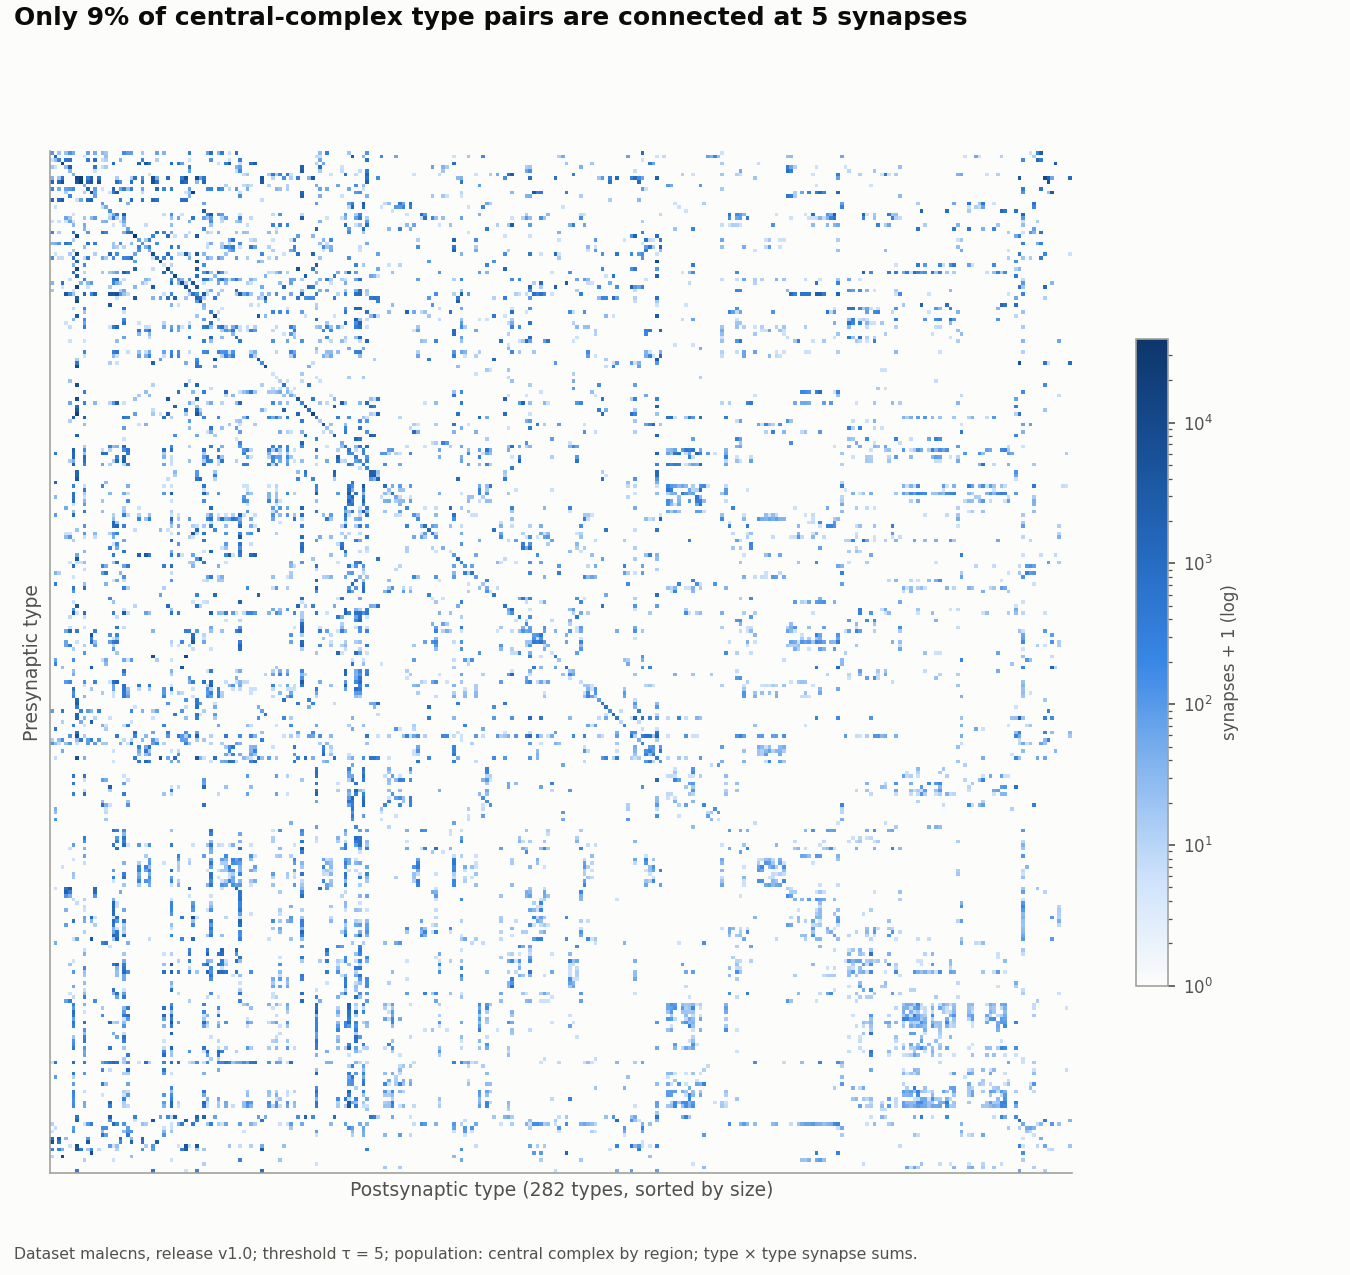

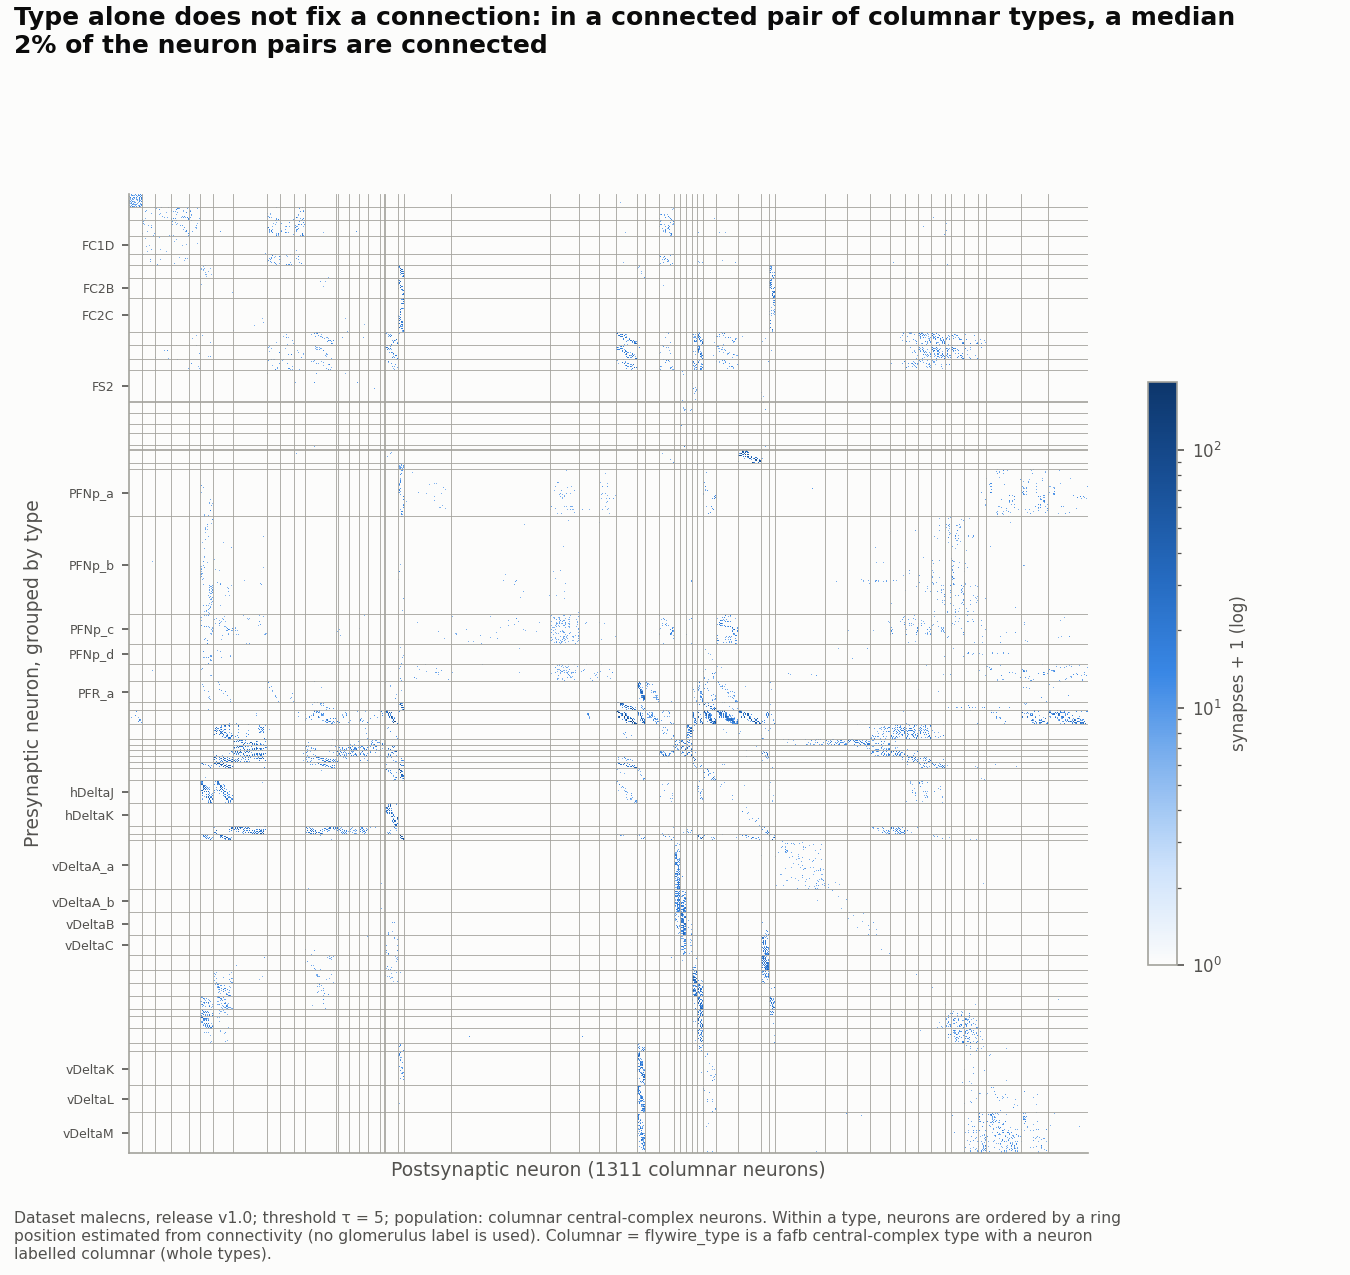

In [14]:
show('E7_malecns', F.fig_e7(mal[0], mal[1], FAFB_COLUMNAR, 'malecns', 'v1.0', type_column='flywire_type'));

In [15]:
(ROOT / 'reports' / 'eda_E_stats.json').write_text(json.dumps(STATS, indent=1, default=float))

4351